In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import joblib
import shap

from scipy.special import expit
from scipy import sparse
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [3]:
MODEL_PATH = ROOT / "models" / "lightgbm_model.joblib"

assert MODEL_PATH.exists(), (
    "LightGBM model not found. "
    "Run Day 6 Cell 15 to save it first."
)

saved = joblib.load(MODEL_PATH)

model = saved["model"]
preprocessor = saved["preprocessor"]
features = saved["features"]

print("Number of original features:", len(features))
print("Model type:", type(model).__name__)
print("Number of trees:", model.n_estimators_)

Number of original features: 27
Model type: LGBMClassifier
Number of trees: 524


In [4]:
DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

X = df[features].copy()
y = df["TARGET"].astype(int)

numeric_cols = X.select_dtypes(
    include=np.number
).columns

X[numeric_cols] = X[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

assert len(X_val) == 61502
assert len(X_test) == 61503
assert list(X.columns) == list(features)

print("Validation rows:", len(X_val))
print("Positive rate:", round(y_val.mean(), 4))

Validation rows: 61502
Positive rate: 0.0807


In [5]:
X_sample = X_val.sample(
    n=1000,
    random_state=42
).copy()

X_sample_processed = preprocessor.transform(X_sample)

feature_names = preprocessor.get_feature_names_out()

if sparse.issparse(X_sample_processed):
    X_shap = X_sample_processed.toarray()
else:
    X_shap = np.asarray(X_sample_processed)

X_shap_df = pd.DataFrame(
    X_shap,
    columns=feature_names,
    index=X_sample.index
)

print("Sample shape:", X_sample.shape)
print("Transformed shape:", X_shap_df.shape)

Sample shape: (1000, 27)
Transformed shape: (1000, 61)


In [6]:
explainer = shap.TreeExplainer(
    model,
    model_output="raw",
    feature_perturbation="tree_path_dependent"
)

shap_values = explainer.shap_values(X_shap_df)

# Handle possible differences across SHAP versions
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

# Binary LightGBM normally returns a 2D matrix
assert shap_values.ndim == 2
assert shap_values.shape == X_shap_df.shape

base_value = np.asarray(
    explainer.expected_value
).reshape(-1)[-1]

print("SHAP values shape:", shap_values.shape)
print("Base value (log-odds):", base_value)
print("Baseline probability:", expit(base_value))

SHAP values shape: (1000, 61)
Base value (log-odds): -2.786018362506936
Baseline probability: 0.058084410188734524


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [7]:
raw_predictions = model.predict(
    X_shap_df,
    raw_score=True
)

reconstructed_raw = (
    base_value + shap_values.sum(axis=1)
)

print(
    "Maximum reconstruction error:",
    np.max(
        np.abs(raw_predictions - reconstructed_raw)
    )
)

assert np.allclose(
    raw_predictions,
    reconstructed_raw,
    atol=1e-4
)

model_prob = model.predict_proba(X_shap_df)[:, 1]

assert np.allclose(
    expit(reconstructed_raw),
    model_prob,
    atol=1e-4
)

print("PASS: SHAP values reconstruct model predictions.")

Maximum reconstruction error: 1.2878587085651816e-14
PASS: SHAP values reconstruct model predictions.


In [8]:
explanation = shap.Explanation(
    values=shap_values,
    base_values=np.repeat(
        base_value, len(X_shap_df)
    ),
    data=X_shap_df.to_numpy(),
    feature_names=list(feature_names)
)

print("Explanation ready.")

Explanation ready.


In [9]:
global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(
        shap_values
    ).mean(axis=0)
})

global_importance = global_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(global_importance.head(20))

,Feature,Mean Absolute SHAP
10,num__EXT_SOURCE_2,0.341380
11,num__EXT_SOURCE_3,0.309148
9,num__EXT_SOURCE_1,0.162424
7,num__employment_years,0.123115
2,num__AMT_ANNUITY,0.108279
1,num__AMT_CREDIT,0.099862
21,num__bureau_debt_credit_ratio,0.074351
47,cat__NAME_EDUCATION_TYPE_Higher education,0.067134
45,cat__NAME_INCOME_TYPE_Working,0.063213
50,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.054231


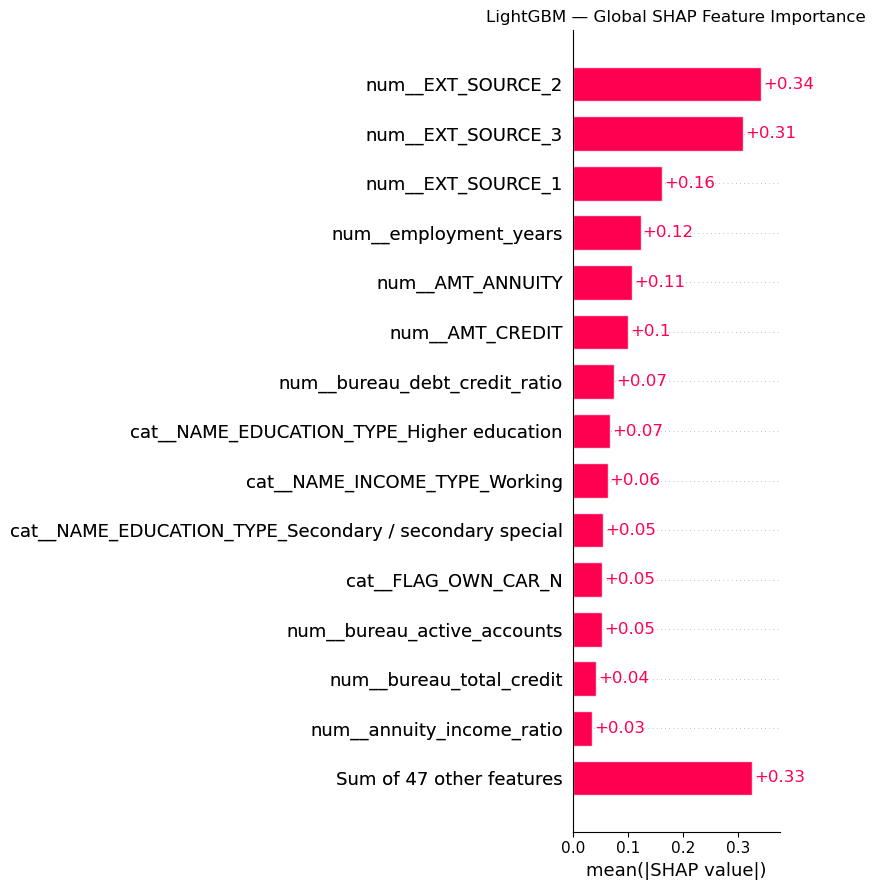

In [10]:
plt.figure()

shap.plots.bar(
    explanation,
    max_display=15,
    show=False
)

plt.title("LightGBM — Global SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_shap_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

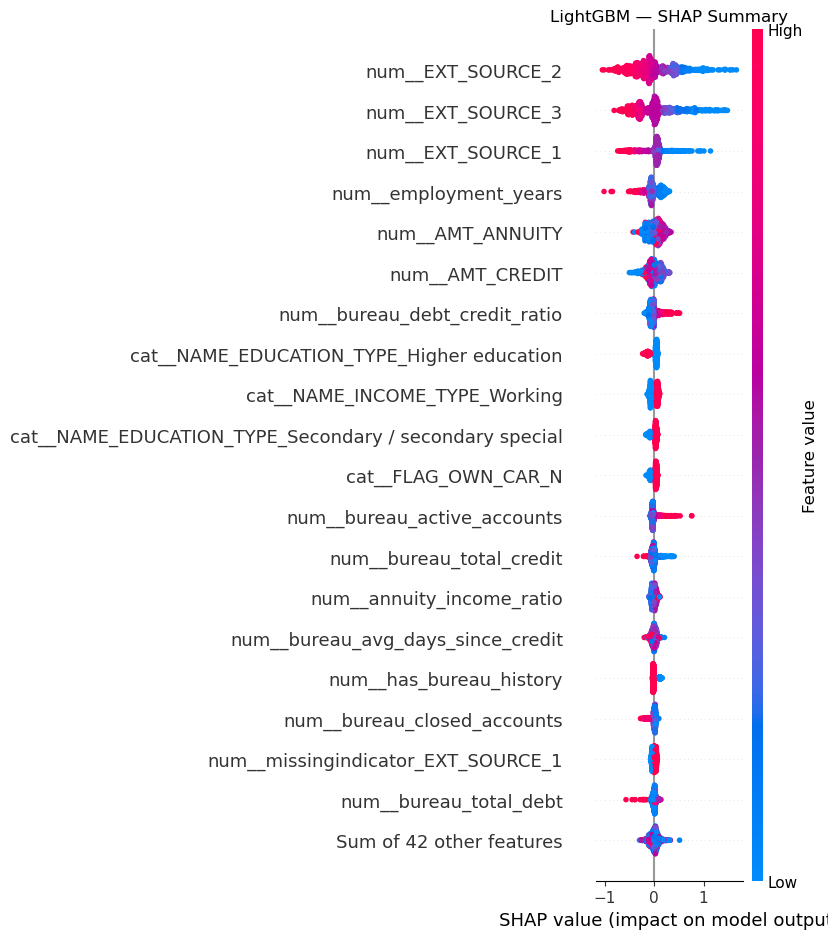

In [11]:
plt.figure()

shap.plots.beeswarm(
    explanation,
    max_display=20,
    show=False
)

plt.title("LightGBM — SHAP Summary")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_shap_beeswarm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

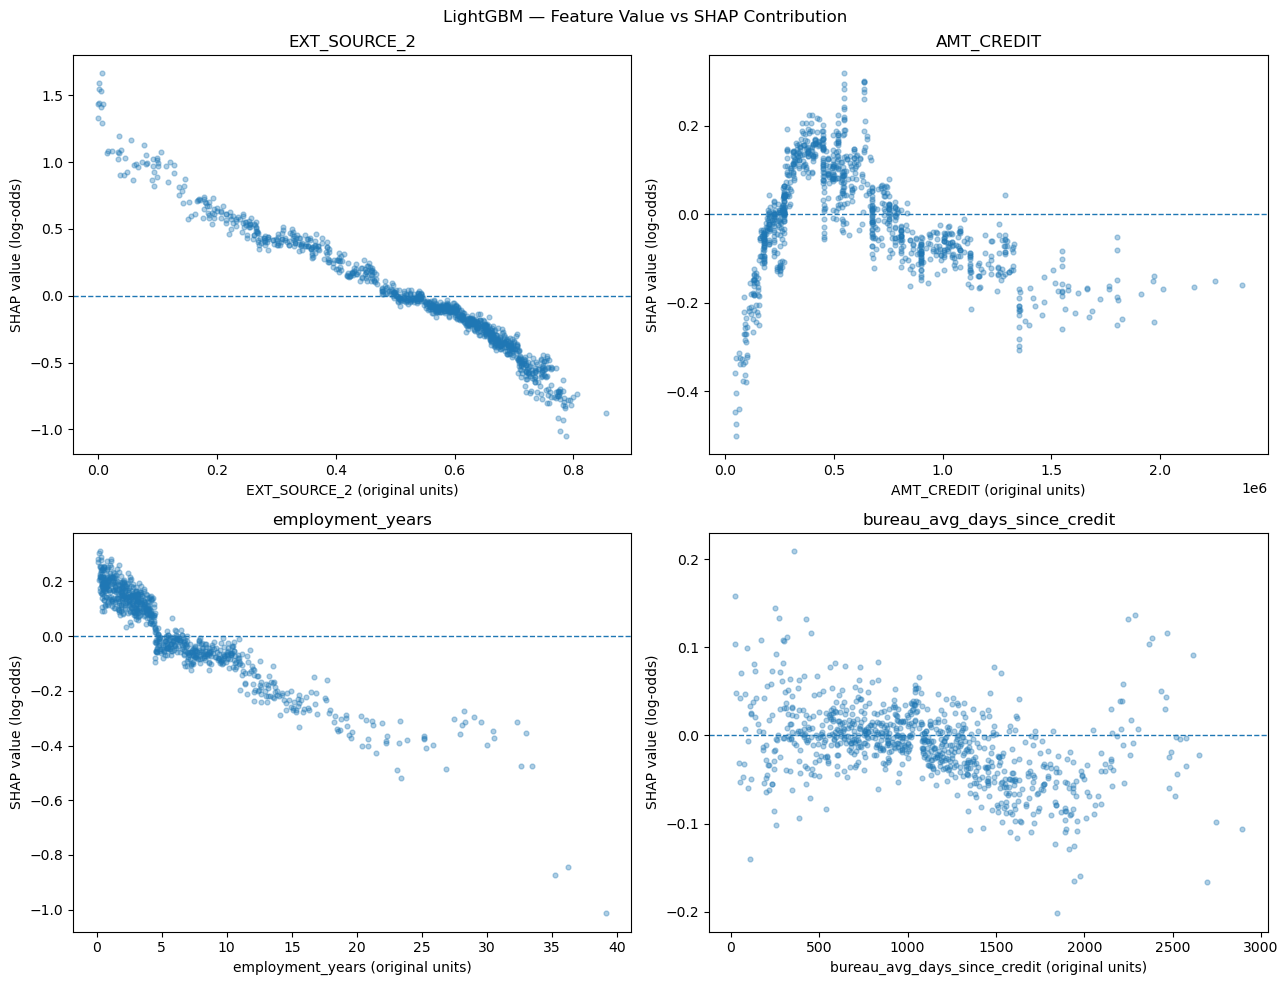

In [12]:
features_to_examine = [
    "EXT_SOURCE_2",
    "AMT_CREDIT",
    "employment_years",
    "bureau_avg_days_since_credit"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for ax, feature in zip(
    axes.flat,
    features_to_examine
):
    transformed_name = f"num__{feature}"

    col_index = list(feature_names).index(
        transformed_name
    )

    ax.scatter(
        X_sample[feature],
        shap_values[:, col_index],
        alpha=0.35,
        s=12
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(feature)
    ax.set_xlabel(
        f"{feature} (original units)"
    )
    ax.set_ylabel("SHAP value (log-odds)")

plt.suptitle(
    "LightGBM — Feature Value vs SHAP Contribution"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_shap_dependence.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [13]:
sample_probabilities = model.predict_proba(
    X_shap_df
)[:, 1]

high_risk_position = int(
    np.argmax(sample_probabilities)
)

low_risk_position = int(
    np.argmin(sample_probabilities)
)

print(
    "Highest sample risk score:",
    round(
        sample_probabilities[high_risk_position],
        4
    )
)

print(
    "Lowest sample risk score:",
    round(
        sample_probabilities[low_risk_position],
        4
    )
)

Highest sample risk score: 0.6016
Lowest sample risk score: 0.0066


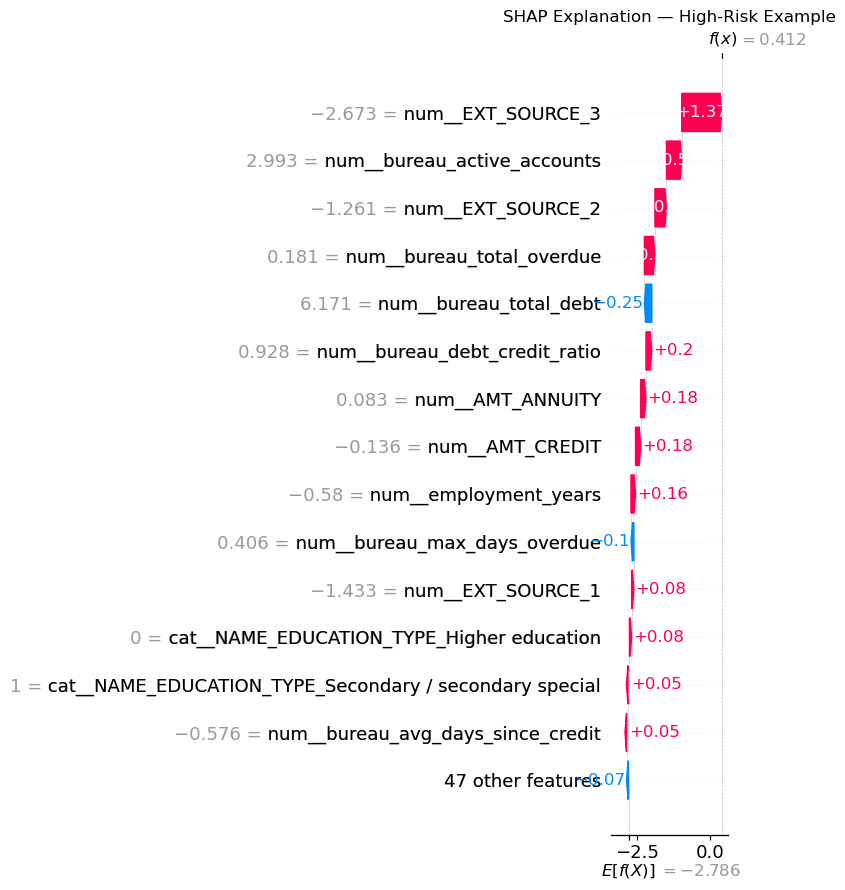

In [14]:
shap.plots.waterfall(
    explanation[high_risk_position],
    max_display=15,
    show=False
)

plt.title("SHAP Explanation — High-Risk Example")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_high_risk_waterfall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

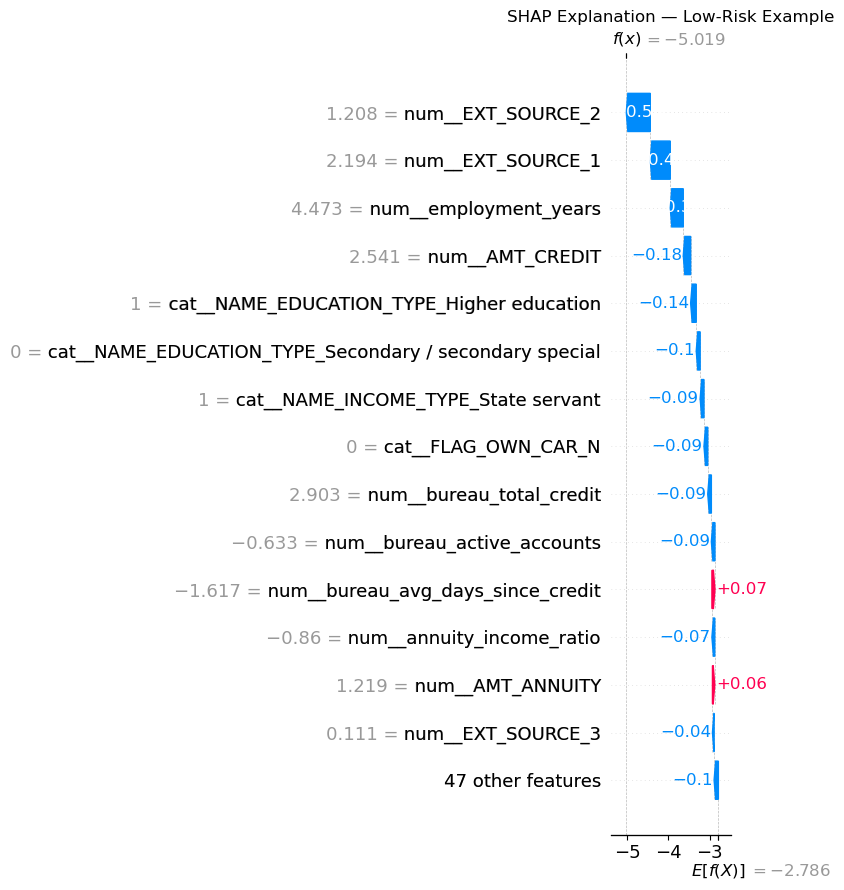

In [15]:
shap.plots.waterfall(
    explanation[low_risk_position],
    max_display=15,
    show=False
)

plt.title("SHAP Explanation — Low-Risk Example")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_low_risk_waterfall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [16]:
risk_deciles = pd.qcut(
    pd.Series(sample_probabilities).rank(
        method="first"
    ),
    q=10,
    labels=False
) + 1

low_mask = risk_deciles.to_numpy() == 1
high_mask = risk_deciles.to_numpy() == 10

segment_rows = []

for i, feature in enumerate(feature_names):
    segment_rows.append({
        "Feature": feature,
        "Low-Risk Mean |SHAP|": (
            np.abs(shap_values[low_mask, i]).mean()
        ),
        "High-Risk Mean |SHAP|": (
            np.abs(shap_values[high_mask, i]).mean()
        )
    })

segment_importance = pd.DataFrame(segment_rows)

segment_importance["Difference"] = (
    segment_importance["High-Risk Mean |SHAP|"]
    - segment_importance["Low-Risk Mean |SHAP|"]
)

display(
    segment_importance.sort_values(
        "Difference",
        ascending=False
    ).head(15)
)

,Feature,Low-Risk Mean |SHAP|,High-Risk Mean |SHAP|,Difference
11,num__EXT_SOURCE_3,0.308764,0.556598,0.247834
10,num__EXT_SOURCE_2,0.407517,0.560265,0.152749
21,num__bureau_debt_credit_ratio,0.060973,0.118025,0.057051
14,num__bureau_active_accounts,0.046997,0.099133,0.052137
45,cat__NAME_INCOME_TYPE_Working,0.045355,0.072134,0.026779
2,num__AMT_ANNUITY,0.095491,0.120646,0.025155
7,num__employment_years,0.117948,0.139021,0.021073
26,num__missingindicator_EXT_SOURCE_1,0.024546,0.040827,0.016282
1,num__AMT_CREDIT,0.104619,0.117152,0.012533
17,num__bureau_total_debt,0.026919,0.033958,0.007039


In [17]:
bureau_shap_columns = [
    i for i, name in enumerate(feature_names)
    if name.startswith("num__bureau_")
    or name == "num__has_bureau_history"
]

bureau_contributions = shap_values[
    :, bureau_shap_columns
].sum(axis=1)

bureau_absolute_importance = np.abs(
    shap_values[:, bureau_shap_columns]
).sum(axis=1)

bureau_summary = pd.DataFrame({
    "Predicted Probability": sample_probabilities,
    "Bureau Net SHAP": bureau_contributions,
    "Bureau Total Absolute SHAP": bureau_absolute_importance
})

display(bureau_summary.describe().round(4))

,Predicted Probability,Bureau Net SHAP,Bureau Total Absolute SHAP
count,1000.0000,1000.0000,1000.0000
mean,0.0770,-0.0198,0.3109
std,0.0758,0.2091,0.1636
min,0.0066,-0.8049,0.0739
25%,0.0287,-0.1598,0.2039
50%,0.0510,-0.0487,0.2550
75%,0.0970,0.1331,0.3813
max,0.6016,0.8576,1.5813


,Mean_Predicted_Risk,Mean_Bureau_SHAP,Mean_Absolute_Bureau_SHAP
Risk Decile,,,
1,0.0146,-0.1581,0.3080
2,0.0216,-0.1277,0.2944
3,0.0289,-0.0931,0.2845
4,0.0370,-0.0363,0.2780
5,0.0455,-0.0385,0.3145
6,0.0579,-0.0213,0.2838
7,0.0741,0.0401,0.3085
8,0.0974,0.0226,0.3199
9,0.1309,0.0384,0.3189


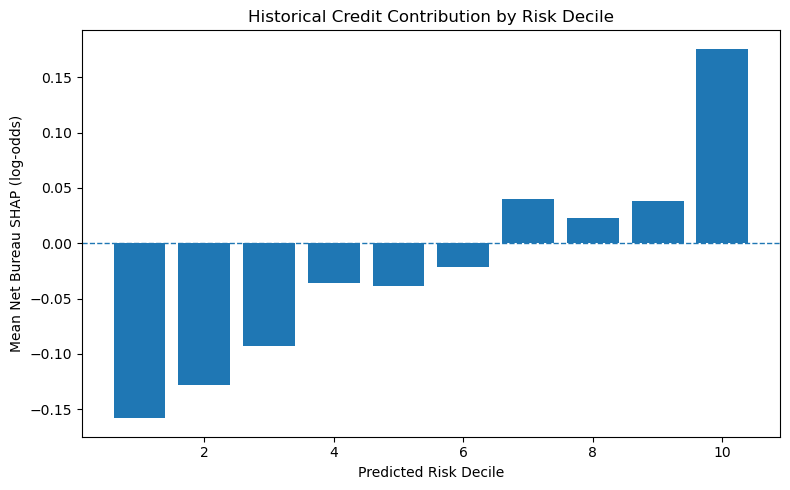

In [18]:
bureau_summary["Risk Decile"] = risk_deciles.to_numpy()

bureau_by_decile = (
    bureau_summary.groupby("Risk Decile")
    .agg(
        Mean_Predicted_Risk=("Predicted Probability", "mean"),
        Mean_Bureau_SHAP=("Bureau Net SHAP", "mean"),
        Mean_Absolute_Bureau_SHAP=(
            "Bureau Total Absolute SHAP", "mean"
        )
    )
)

display(bureau_by_decile.round(4))

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    bureau_by_decile.index,
    bureau_by_decile["Mean_Bureau_SHAP"]
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Predicted Risk Decile")
ax.set_ylabel("Mean Net Bureau SHAP (log-odds)")
ax.set_title("Historical Credit Contribution by Risk Decile")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day08_bureau_shap_by_decile.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [19]:
global_importance.to_csv(
    ROOT / "reports" / "day08_shap_importance.csv",
    index=False
)

segment_importance.to_csv(
    ROOT / "reports" / "day08_segment_importance.csv",
    index=False
)

bureau_by_decile.to_csv(
    ROOT / "reports" / "day08_bureau_contributions.csv"
)

print("Day 8 aggregate results saved.")

Day 8 aggregate results saved.
